# E-Commerce A/B Testing: Checkout Optimization
**Author:** Kristina Nuić

## Project Overview
An online retailer is testing a new "One-Click Checkout" button (Treatment Group) against their standard multi-page checkout process (Control Group). The goal of this project is to analyze the test results and mathematically determine if the new checkout feature significantly increases the conversion rate.

**Tools & Techniques Used:**
* **Language:** Python
* **Libraries:** Pandas, NumPy, SciPy, Matplotlib, Seaborn
* **Techniques:** A/B Testing, Data Cleaning & Preprocessing, Statistical Hypothesis Testing (Chi-Square), Exploratory Data Analysis (EDA)

## Data Generation (Simulation)
Since real-world A/B test data is often proprietary, this script generates a realistic synthetic dataset simulating website traffic over a 14-day period. 

The generated dataset deliberately includes:
* A 50/50 user split between the **Control** (old checkout) and **Treatment** (new checkout) groups.
* **Intentional routing errors** (~5% of the time) to simulate real-world tracking glitches, which will be identified and cleaned in the next step.
* **Simulated conversion rates** where the Treatment group has a slightly higher probability of success, allowing us to perform statistical significance testing.

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# 1. Set parameters for our mock data
np.random.seed(42) # Ensures we get the exact same random numbers every time
num_users = 3000

# 2. Generate User IDs and Groups
user_ids = range(1, num_users + 1)
# Randomly assign users to control (old checkout) or treatment (new checkout)
groups = np.random.choice(['control', 'treatment'], size=num_users, p=[0.5, 0.5])

# 3. Assign Landing Pages (Injecting some deliberate errors for us to clean later!)
landing_pages = []
for group in groups:
    if np.random.rand() < 0.05: # 5% of the time, the system made an error
        landing_pages.append('old_page' if group == 'treatment' else 'new_page')
    else:
        landing_pages.append('old_page' if group == 'control' else 'new_page')

# 4. Generate Conversions (The treatment group will have a slightly higher success rate)
converted = []
for group in groups:
    if group == 'control':
        converted.append(np.random.choice([0, 1], p=[0.88, 0.12])) # 12% conversion
    else:
        converted.append(np.random.choice([0, 1], p=[0.85, 0.15])) # 15% conversion

# 5. Generate Timestamps (Random times over a 14-day testing period)
start_date = datetime(2026, 9, 1)
timestamps = [start_date + timedelta(days=np.random.randint(0, 14), 
                                     hours=np.random.randint(0, 24), 
                                     minutes=np.random.randint(0, 60)) 
              for _ in range(num_users)]

# 6. Combine into a Pandas DataFrame
df = pd.DataFrame({
    'user_id': user_ids,
    'timestamp': timestamps,
    'group': groups,
    'landing_page': landing_pages,
    'converted': converted
})

# 7. Save to CSV and display the first few rows
df.to_csv('ab_test_data.csv', index=False)
print("Data generated and saved as 'ab_test_data.csv'!")
display(df.head())

Data generated and saved as 'ab_test_data.csv'!


,user_id,timestamp,group,landing_page,converted
0,1,2026-09-05 17:14:00,control,old_page,0
1,2,2026-09-12 16:56:00,treatment,new_page,0
2,3,2026-09-02 05:16:00,treatment,new_page,1
3,4,2026-09-01 19:08:00,treatment,new_page,0
4,5,2026-09-11 04:22:00,control,old_page,0


## 1. Data Cleaning & Sanity Checks
In real-world A/B testing, routing errors occur. We must verify that users in the Control group only saw the old page, and users in the Treatment group only saw the new page. Any mismatched records will be removed to prevent data contamination.

In [2]:
# 1. Use a crosstab to visually check if the groups match the correct landing pages
print("--- Group vs. Landing Page Distribution ---")
display(pd.crosstab(df['group'], df['landing_page']))

# 2. Mathematically isolate the mismatched rows
mismatched_rows = df[((df['group'] == 'control') & (df['landing_page'] == 'new_page')) | 
                     ((df['group'] == 'treatment') & (df['landing_page'] == 'old_page'))]

print(f"\nTotal corrupted rows found: {len(mismatched_rows)}")

--- Group vs. Landing Page Distribution ---


landing_page,new_page,old_page
group,,
control,69,1416
treatment,1447,68



Total corrupted rows found: 137


In [3]:
# Keep only the rows where the group and landing page strictly align
df_clean = df[((df['group'] == 'control') & (df['landing_page'] == 'old_page')) | 
              ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))]

# Verify the exact number of remaining valid rows
print(f"Original dataset: {df.shape[0]} rows")
print(f"Cleaned dataset: {df_clean.shape[0]} rows")

Original dataset: 3000 rows
Cleaned dataset: 2863 rows


## 2. Exploratory Data Analysis (EDA)
Before running statistical models, we calculate the baseline conversion rates for both groups to observe the initial performance difference.

--- Conversion Rates (%) ---
group
control      10.381356
treatment    14.996545
Name: converted, dtype: float64




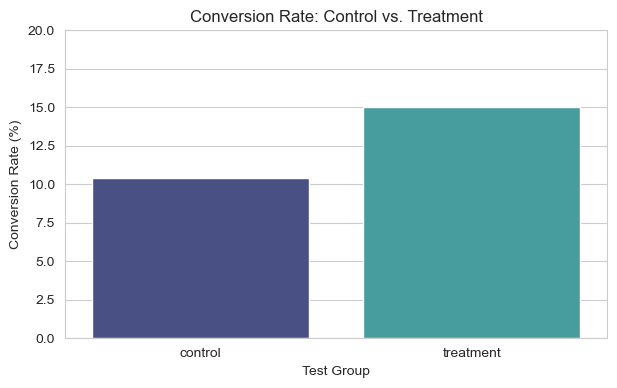

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the conversion rate per group
conversion_rates = df_clean.groupby('group')['converted'].mean() * 100

print("--- Conversion Rates (%) ---")
print(conversion_rates)
print("\n")

# 2. Visualize the results
sns.set_style("whitegrid")
plt.figure(figsize=(7, 4))
sns.barplot(x=conversion_rates.index, y=conversion_rates.values, hue=conversion_rates.index, palette="mako", legend=False)

plt.title('Conversion Rate: Control vs. Treatment')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Test Group')
plt.ylim(0, 20) 

plt.show()

## 3. Statistical Testing (Chi-Square Test)
To prove the observed increase in conversions isn't due to random chance, we perform a Chi-Square test with a standard significance level of $\alpha = 0.05$.

In [5]:
from scipy.stats import chi2_contingency

# 1. Create a contingency table (Group vs. Converted Success/Failure)
contingency_table = pd.crosstab(df_clean['group'], df_clean['converted'])
print("--- Contingency Table ---")
display(contingency_table)

# 2. Run the Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"\nCalculated p-value: {p_value:.6f}")

# 3. Business interpretation
alpha = 0.05
print("\n--- Statistical Verdict ---")
if p_value < alpha:
    print("Result: Statistically Significant.")
    print("Recommendation: Deploy the new checkout page. The conversion increase is real.")
else:
    print("Result: Not Statistically Significant.")
    print("Recommendation: Do not deploy. The observed difference is likely random noise.")

--- Contingency Table ---


converted,0,1
group,,
control,1269,147
treatment,1230,217



Calculated p-value: 0.000262

--- Statistical Verdict ---
Result: Statistically Significant.
Recommendation: Deploy the new checkout page. The conversion increase is real.


## 4. Business Recommendation
**Result:** The $p$-value (0.000262) is significantly lower than our alpha threshold (0.05).

**Conclusion:** The results are statistically significant. The observed increase in the conversion rate is directly caused by the new checkout design, not random chance.

**Action:** Deploy the new "One-Click Checkout" page to all users.